c:\Users\SOUMYA\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\SOUMYA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Preprocessing Test: 100%|██████████| 2000/2000 [00:00<00:00, 6977.28it/s]
PCA Components: 3187
KNN Tuning: 100%|██████████| 6/6 [00:08<00:00,  1.48s/it]
Best K: 9
KMeans Elbow: 100%|██████████| 8/8 [00:01<00:00,  7.36it/s]
BoW Vocabulary: 5000
TF-IDF Vocabulary: 5000


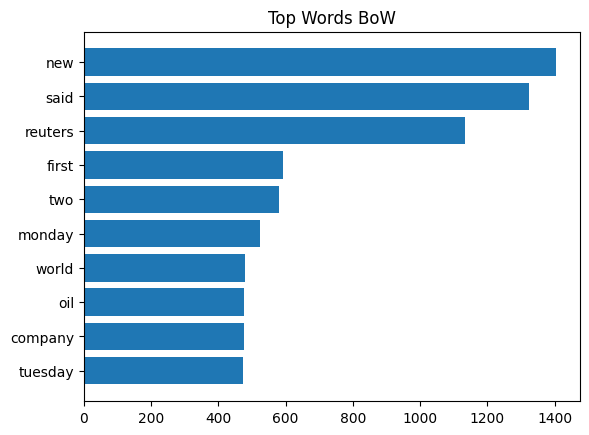

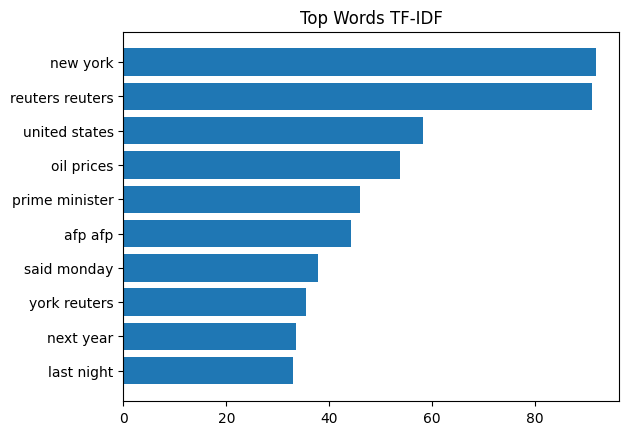

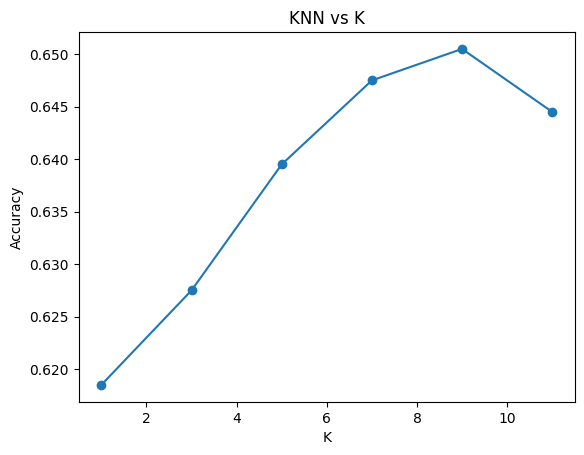

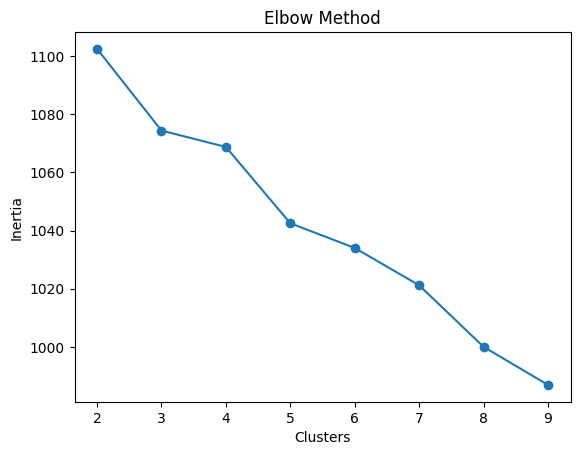

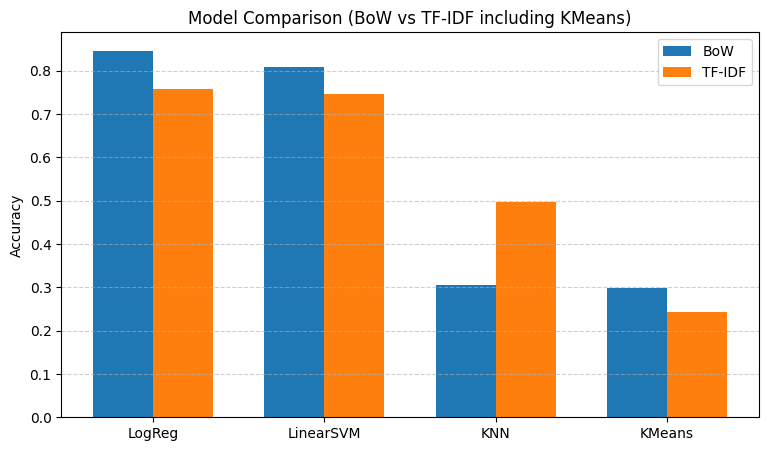


====== FINAL RESULTS (Accuracy + F1) ======

BoW Results:
LogReg: Acc=0.8465, F1=0.8474, Recall=0.8482, Precision=0.8472
LinearSVM: Acc=0.8085, F1=0.8095, Recall=0.8102, Precision=0.8092
KNN: Acc=0.2790, F1=0.2755, Recall=0.2803, Precision=0.2769
KMeans: Acc=0.2980, F1=0.2468, Recall=0.2975, Precision=0.3547

TF-IDF Results:
LogReg: Acc=0.7575, F1=0.7632, Recall=0.7590, Precision=0.7851
LinearSVM: Acc=0.7465, F1=0.7518, Recall=0.7480, Precision=0.7722
KNN: Acc=0.4960, F1=0.4840, Recall=0.5008, Precision=0.5400
KMeans: Acc=0.2420, F1=0.0983, Recall=0.2505, Precision=0.3104


c:\Users\SOUMYA\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [1]:
# Load data
from data_loader import load_data
X_train, X_test, y_train, y_test = load_data()

# Imports
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, recall_score, precision_score
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import sys

np.random.seed(42)

# Preprocessing
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    
    tokens = text.split()
    
    tokens = [
        w for w in tokens
        if w not in stop_words
        and len(w) > 2
        and not w.isnumeric()
    ]
    
    return " ".join(tokens)

X_train = [preprocess(t) for t in tqdm(X_train, desc="Preprocessing Train", file=sys.stdout)]
X_test = [preprocess(t) for t in tqdm(X_test, desc="Preprocessing Test", file=sys.stdout)]

# Vectorization
bow = CountVectorizer(max_features=5000)
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(2,2))

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# SVD
svd = TruncatedSVD(n_components=100)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)


# PCA
X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_dense)
X_test_pca = pca.transform(X_test_dense)
print("PCA Components:", pca.n_components_)

# Models
models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "LinearSVM": LinearSVC()
}

results = {}

for name, model in models.items():
    model.fit(X_train_svd, y_train)
    preds = model.predict(X_test_svd)
    acc = accuracy_score(y_test, preds)
    results[name] = acc

# KNN
k_values = [1,3,5,7,9,11]
knn_acc = []

for k in tqdm(k_values, desc="KNN Tuning", file=sys.stdout):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_svd, y_train)
    preds = model.predict(X_test_svd)
    acc = accuracy_score(y_test, preds)
    knn_acc.append(acc)

best_k = k_values[np.argmax(knn_acc)]
print("Best K:", best_k)

# KMeans Elbow
inertia = []
k_range = range(2,10)

for k in tqdm(k_range, desc="KMeans Elbow", file=sys.stdout):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_svd)
    inertia.append(kmeans.inertia_)

# Final KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_train_svd)
preds = kmeans.predict(X_test_svd)
kmeans_acc = accuracy_score(y_test, preds)
results["KMeans"] = kmeans_acc


# Vocabulary
print("BoW Vocabulary:", len(bow.vocabulary_))
print("TF-IDF Vocabulary:", len(tfidf.vocabulary_))

# Top Words BoW
sum_words = np.array(X_train_bow.sum(axis=0)).flatten()
words = bow.get_feature_names_out()
top = sum_words.argsort()[-10:]

plt.barh([words[i] for i in top], sum_words[top])
plt.title("Top Words BoW")
plt.show()

# Top Words TF-IDF
sum_words = np.array(X_train_tfidf.sum(axis=0)).flatten()
words = tfidf.get_feature_names_out()
top = sum_words.argsort()[-10:]

plt.barh([words[i] for i in top], sum_words[top])
plt.title("Top Words TF-IDF")
plt.show()

# KNN Graph
plt.plot(k_values, knn_acc, marker='o')
plt.title("KNN vs K")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.show()

# Elbow Graph
plt.plot(k_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.show()

# Add KMeans for BoW
kmeans_bow = KMeans(n_clusters=4, random_state=42)
kmeans_bow.fit(X_train_bow)

bow_results = {}
tfidf_results = {}

for name, model in models.items():
    model.fit(X_train_bow, y_train)
    bow_results[name] = accuracy_score(y_test, model.predict(X_test_bow))

    model.fit(X_train_tfidf, y_train)
    tfidf_results[name] = accuracy_score(y_test, model.predict(X_test_tfidf))

# KNN
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_bow, y_train)
bow_results["KNN"] = accuracy_score(y_test, knn_model.predict(X_test_bow))

knn_model.fit(X_train_tfidf, y_train)
tfidf_results["KNN"] = accuracy_score(y_test, knn_model.predict(X_test_tfidf))

# KMeans
bow_results["KMeans"] = accuracy_score(y_test, kmeans_bow.predict(X_test_bow))

kmeans_tfidf = KMeans(n_clusters=4, random_state=42)
kmeans_tfidf.fit(X_train_tfidf)
tfidf_results["KMeans"] = accuracy_score(y_test, kmeans_tfidf.predict(X_test_tfidf))

labels = list(tfidf_results.keys())

bow_acc = [bow_results.get(label, 0) for label in labels]
tfidf_acc = list(tfidf_results.values())

x = range(len(labels))

plt.figure(figsize=(9,5))
plt.bar(x, bow_acc, width=0.35, label="BoW")
plt.bar([i + 0.35 for i in x], tfidf_acc, width=0.35, label="TF-IDF")

plt.xticks([i + 0.175 for i in x], labels)
plt.ylabel("Accuracy")
plt.title("Model Comparison (BoW vs TF-IDF including KMeans)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

print("\n====== FINAL RESULTS (Accuracy + F1) ======")

print("\nBoW Results:")
for name, model in models.items():
    model.fit(X_train_bow, y_train)
    preds = model.predict(X_test_bow)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    recall = recall_score(y_test, preds, average='macro')
    precision = precision_score(y_test, preds, average='macro')

    print(f"{name}: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")

# KNN (BoW)
preds = knn_model.predict(X_test_bow)
acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average='macro')
recall = recall_score(y_test, preds, average='macro')
precision = precision_score(y_test, preds, average='macro')
print(f"KNN: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")

# KMeans (BoW)
kmeans_bow = KMeans(n_clusters=4, random_state=42)
kmeans_bow.fit(X_train_bow)
preds = kmeans_bow.predict(X_test_bow)
acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average='macro')
recall = recall_score(y_test, preds, average='macro')
precision = precision_score(y_test, preds, average='macro')
print(f"KMeans: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")

print("\nTF-IDF Results:")
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_test_tfidf)
    recall = recall_score(y_test, preds, average='macro')
    precision = precision_score(y_test, preds, average='macro')

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')

    print(f"{name}: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")

# KNN (TF-IDF)
preds = knn_model.predict(X_test_tfidf)
acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average='macro')
recall = recall_score(y_test, preds, average='macro')
precision = precision_score(y_test, preds, average='macro')
print(f"KNN: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")

# KMeans (TF-IDF)
preds = kmeans_tfidf.predict(X_test_tfidf)
acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average='macro')
recall = recall_score(y_test, preds, average='macro')
precision = precision_score(y_test, preds, average='macro')
print(f"KMeans: Acc={acc:.4f}, F1={f1:.4f}, Recall={recall:.4f}, Precision={precision:.4f}")